# 08 Clusterbenchmark: K-Means, Ward, GMM und HDBSCAN

Teil 3: Clustering

**Worum es geht**
- Vier Clusterverfahren auf denselben Stationsmerkmalen und mit derselben Vorverarbeitung wie in Notebook 07 vergleichen.
- Bewertung mit Silhouette (immer zusammen mit den Clustergrößen), Bootstrap-ARI als Maß für Stabilität und Abgleich mit den Begehungen.
- Vorab festgelegt: k = 3 (Begründung in Abschnitt 4) und Seed 42 überall.
- Gerechnet wird auf den 93 HAST aus Notebook 00. BHKW, Kessel und Temperaturfühler sind dort schon raus.

**Daten**
- liest: `data/processed/hast_features.csv` (Stand nach dem `full_load_hours`-Fix), `data/processed/inspections_tidy.csv`
- schreibt: `data/processed/cluster_benchmark.csv` und `data/processed/cluster_benchmark.json`
- vorher ausführen: Notebook 00; `inspections_tidy.csv` entsteht mit `python -m src.main`

**Code**
- Adressabgleich über `_normalize_address` aus `src/load_data.py`

## 1 Setup und Daten laden

- Sucht die Projektwurzel (nach oben, bis `data/processed` auftaucht) und hängt sie an `sys.path`, damit `src/` importierbar ist.
- Prüft, dass alle drei Eingabedateien existieren.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import AgglomerativeClustering, HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.facecolor"] = "white"

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "processed").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.load_data import _normalize_address  #noqa: E402

FEATURES_PATH = ROOT / "data" / "processed" / "hast_features.csv"
INSPECTIONS_PATH = ROOT / "data" / "processed" / "inspections_tidy.csv"
for path in (FEATURES_PATH, INSPECTIONS_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"{path} nicht gefunden")

features_all = pd.read_csv(FEATURES_PATH)
print(f"{len(features_all)} HAST-Profile geladen")
cov = features_all["coverage"]
print(f"coverage: {cov.min():.1%} bis {cov.max():.1%} (Median {cov.median():.1%}) — "
      "Qualitätsdimension, wird mitgeführt, aber nicht als Feature genutzt")
features_all.drop(columns="address").head()  #ohne Adressen

93 HAST-Profile geladen
coverage: 45.6% bis 100.0% (Median 79.0%) — Qualitätsdimension, wird mitgeführt, aber nicht als Feature genutzt


,rt_mean_winter,rt_p95,dt_mean_loaded,dt_std_loaded,rt_above_50_share_loaded,summer_flow_share,summer_flow_baseline,flow_ceiling_slope_per_month,peak_load_share,p95_load_share,flow_short_cycle_power,idle_share,energy_kwh_year,full_load_hours,Zählernummer,anschlusswert_kw,coverage,n_rows,n_hours
0,45.614801,58.5,29.575008,8.451971,0.319709,0.605441,20.0,-6.152177,1.7325,0.983,0.139289,0.354887,4.143699e+04,1195.872608,53198226,20.0,0.686198,22193,32342
1,41.199395,49.1,31.884356,5.927171,0.033037,0.085217,0.0,-4.766754,NaN,NaN,0.128650,0.447939,1.436235e+04,930.143977,58177363,NaN,0.609600,13513,22167
2,53.493089,59.5,22.788473,5.697562,0.651170,0.314597,0.0,-11.896678,NaN,NaN,0.133458,0.298658,3.066944e+04,2541.806879,58177384,NaN,0.511487,9017,17629
3,58.711979,74.2,NaN,NaN,0.999921,0.912609,7820.0,228.286667,NaN,NaN,0.101974,0.060983,1.911474e+06,5805.045621,58202380,NaN,0.609555,13512,22167
4,43.459029,63.5,23.628571,9.528109,0.347671,0.102609,0.0,-0.936316,NaN,NaN,0.243884,0.588475,5.866872e+03,486.231757,61620222,NaN,0.609798,13518,22168


- 93 HAST-Profile geladen.
- `coverage` (Anteil belegter Messstunden) reicht von 45,6 % bis 100 %, Median 79 %.
- `coverage` wird nur berichtet, nicht geclustert. Sonst clustert man Datenqualität statt Betriebsverhalten.

## 2 Kontrolle: nur HAST

- Notebook 00 nimmt 8 Zähler raus, die laut ÜZ keine HAST sind: BHKW 86792512, die HHS-Kessel I bis IV, den Ölspitzenkessel und zwei Temperaturfühler.
- Die Zelle prüft, dass keiner davon in den Features steht. Sonst erst Notebook 00 neu ausführen.
- Frühere Läufe haben mit und ohne BHKW gerechnet. Das entfällt, seit das BHKW schon in Notebook 00 rausfällt.

In [2]:
#NB00 nimmt diese 8 Zähler schon raus (laut ÜZ keine HAST)
NICHT_HAST = {41566330, 41566331, 41566332, 41628863, 41704231, 41704232, 48090145, 86792512}
uebrig = sorted(NICHT_HAST & set(features_all["Zählernummer"]))
assert not uebrig, f"Nicht-HAST in den Features: {uebrig}, zuerst Notebook 00 neu ausführen"
varianten = {"HAST": features_all}
print(f"{len(features_all)} HAST, keine Nicht-HAST in den Features")

93 HAST, keine Nicht-HAST in den Features


- 93 HAST, keiner der 8 Nicht-HAST steht noch in den Features.

## 3 Vorverarbeitung wie in Notebook 07

- Dieselben 10 Merkmale wie in Notebook 07: ohne Dopplungen (`rt_p95`, `rt_above_50_share_loaded`, `summer_flow_share`) und ohne das Größenmaß `energy_kwh_year`.
- Dieselbe Kette: fehlende Werte mit dem Median füllen, auf 1. und 99. Perzentil kappen, standardisieren.
- `vorverarbeiten()` bündelt die Kette, damit alle Verfahren genau dieselbe Matrix bekommen.

In [3]:
CLUSTER_FEATURES = [
    "rt_mean_winter", "dt_mean_loaded", "dt_std_loaded",
    "summer_flow_baseline", "flow_ceiling_slope_per_month",
    "peak_load_share", "p95_load_share", "flow_short_cycle_power",
    "idle_share", "full_load_hours",
]

X_raw = features_all[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan)
missing_share = (X_raw.isna().mean() * 100).sort_values(ascending=False)
print("Anteil fehlender Werte je Cluster-Feature:")
display(missing_share.round(1).to_frame("% fehlend"))


def vorverarbeiten(df):
    """Median-Imputation -> Clipping 1./99. Perzentil -> StandardScaler."""
    raw = df[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan)
    imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(raw),
                       columns=CLUSTER_FEATURES, index=df.index)
    bounds = imp.quantile([0.01, 0.99])
    clipped = imp.clip(lower=bounds.loc[0.01], upper=bounds.loc[0.99], axis=1)
    return StandardScaler().fit_transform(clipped)


X_varianten = {name: vorverarbeiten(df) for name, df in varianten.items()}
for name, X in X_varianten.items():
    print(f"Matrix {X.shape[0]} HAST x {X.shape[1]} Features")

Anteil fehlender Werte je Cluster-Feature:


,% fehlend
peak_load_share,6.5
p95_load_share,6.5
dt_mean_loaded,1.1
dt_std_loaded,1.1
rt_mean_winter,0.0
summer_flow_baseline,0.0
flow_ceiling_slope_per_month,0.0
flow_short_cycle_power,0.0
idle_share,0.0
full_load_hours,0.0


Matrix 93 HAST x 10 Features


- Fehlende Werte: `peak_load_share` und `p95_load_share` je 6,5 %, `dt_mean_loaded` und `dt_std_loaded` je 1,1 %.
- `full_load_hours` ist auf dem korrigierten Stand: höchstens 5 805 h statt 14 689 h vor dem Fix.

## 4 Wahl von k (Elbow und Silhouette)

- K-Means für k = 2 bis 8. Inertia = Summe der quadrierten Abstände zum Zentrum, Silhouette = Trennschärfe von −1 bis 1.
- k wird im Text begründet und fest gesetzt, nicht automatisch über die beste Silhouette. In einem früheren Lauf von Notebook 07 lagen k-Werte teils nur 0,002 auseinander; das ist Rauschen.
- Hilfslinien bei 0,25 (darunter keine Typen, sondern Schnitte durch ein Kontinuum) und 0,5 (klare Trennung).

,inertia,silhouette
variante,HAST,HAST
k,,
2,748.714,0.237
3,658.381,0.219
4,573.408,0.157
5,515.678,0.165
6,454.342,0.185
7,411.416,0.170
8,367.451,0.194


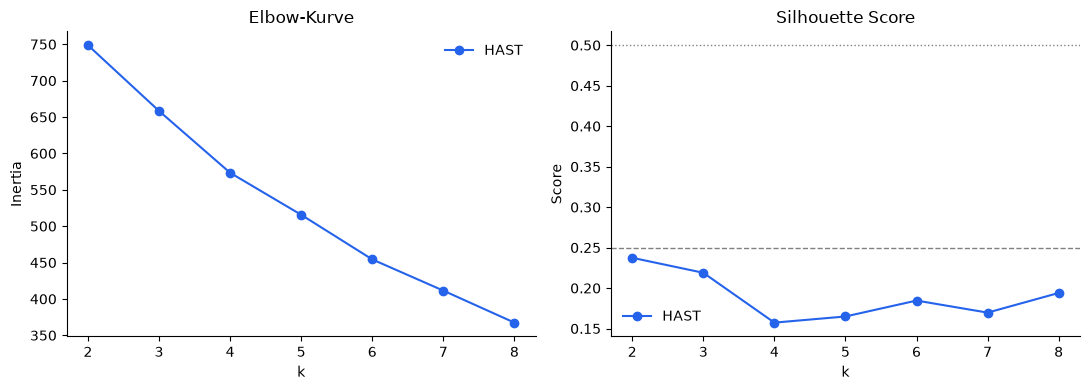

In [4]:
k_values = list(range(2, 9))
sweep_rows = []
for vname, X in X_varianten.items():
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
        sweep_rows.append({
            "variante": vname, "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette_score(X, model.labels_),
        })
sweep = pd.DataFrame(sweep_rows)
display(sweep.pivot(index="k", columns="variante", values=["inertia", "silhouette"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
farben = {"HAST": "#2563EB"}
for vname, grp in sweep.groupby("variante"):
    axes[0].plot(grp["k"], grp["inertia"], marker="o", color=farben[vname], label=vname)
    axes[1].plot(grp["k"], grp["silhouette"], marker="o", color=farben[vname], label=vname)
axes[0].set(title="Elbow-Kurve", xlabel="k", ylabel="Inertia")
axes[1].set(title="Silhouette Score", xlabel="k", ylabel="Score")
axes[1].axhline(0.25, color="grey", lw=1, ls="--")
axes[1].axhline(0.5, color="grey", lw=1, ls=":")
for ax in axes:
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

- k = 2 hat die beste Silhouette (0,237) bei 31/62. Das ist dieselbe Trennung wie in Notebook 07: auffällig gegen Normalbetrieb.
- Früher lag k = 2 mit BHKW und Kesseln bei 0,599, weil nur die Ausreißer abgetrennt wurden (97/3). Seit Notebook 00 diese Zähler entfernt, ist der Effekt weg.
- Ab k = 3 liegen alle K-Means-Werte zwischen 0,16 und 0,22, also unter 0,25. Die Inertia fällt ohne klaren Knick; die Elbow-Methode entscheidet hier nichts.
- Festlegung k = 3: der Konsistenz-Anker aus der Voranalyse (Abschnitt 7). k = 3 trennt zusätzlich die Ausreißer ab (30/60/3) und behält die schwach gespreizte Gruppe (n = 30, Abschnitt 8). k ≥ 4 zerlegt die Masse weiter (Splitter ab n = 2), ohne bessere Silhouette.

In [5]:
K = 3        #Begründung im Text oben
SEED = 42


def fit_kmeans(X, k, seed=SEED):
    return KMeans(n_clusters=k, n_init=20, random_state=seed).fit(X).labels_


def fit_ward(X, k, seed=SEED):
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X).labels_


def fit_gmm(X, k, seed=SEED):
    return GaussianMixture(n_components=k, covariance_type="full",
                           n_init=5, random_state=seed).fit(X).predict(X)


FITTER = {"K-Means": fit_kmeans, "Ward": fit_ward, "GMM": fit_gmm}


def groessen(labels):
    counts = pd.Series(labels).value_counts().sort_index()
    return "/".join(str(int(n)) for n in counts)


def sichere_silhouette(X, labels):
    lab = np.asarray(labels)
    if len(np.unique(lab)) < 2:
        return np.nan
    return silhouette_score(X, lab)

- K-Means und GMM mit Seed 42; Ward ist deterministisch und braucht keinen Seed.
- GMM (Gaussian Mixture Model, Mischung von Normalverteilungen) mit voller Kovarianz: Cluster dürfen elliptisch statt kugelig sein. Das passt zu korrelierten Merkmalen wie `rt_mean_winter` und `dt_mean_loaded`.
- `groessen()` gibt die Clustergrößen als „31/62“ aus. Die Silhouette wird in diesem Benchmark nie ohne Größen genannt.
- `sichere_silhouette()` liefert NaN statt Absturz, wenn ein Verfahren nur einen Cluster findet.

## 5 Verfahren und k: Silhouette und Clustergrößen

- K-Means, Ward (hierarchisch: legt schrittweise die Gruppen zusammen, deren Vereinigung die Streuung am wenigsten erhöht) und GMM für k = 2 bis 8.
- HDBSCAN (dichtebasiert: Cluster sind dichte Bereiche) hat kein k, sondern eine Mindestgröße `min_cluster_size` (mcs). Getestet werden 3, 5 und 8.
- Punkte, die HDBSCAN keinem Cluster zuordnet, gelten als Rauschen (Label −1). Sie gehen nicht in die Silhouette ein; ihr Anteil wird ausgewiesen.

In [6]:
rows = []
hdbscan_labels = {}
for vname, X in X_varianten.items():
    for mname, fn in FITTER.items():
        for k in k_values:
            lab = fn(X, k)
            rows.append({"variante": vname, "verfahren": mname, "k": k,
                         "silhouette": sichere_silhouette(X, lab),
                         "größen": groessen(lab)})
    for mcs in (3, 5, 8):
        lab = HDBSCAN(min_cluster_size=mcs).fit(X).labels_
        if mcs == 3:
            hdbscan_labels[vname] = lab
        noise = int((lab == -1).sum())
        ok = lab != -1
        sil = sichere_silhouette(X[ok], lab[ok]) if ok.sum() > 1 else np.nan
        groesse = groessen(lab[ok]) + (f" (+{noise} Rauschen)" if noise else "")
        rows.append({"variante": vname, "verfahren": f"HDBSCAN mcs={mcs}", "k": "-",
                     "silhouette": sil, "größen": groesse})

ergebnis = pd.DataFrame(rows)
display(ergebnis.round(3))

/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,variante,verfahren,k,silhouette,größen
0,HAST,K-Means,2,0.237,31/62
1,HAST,K-Means,3,0.219,30/60/3
2,HAST,K-Means,4,0.157,24/37/3/29
3,HAST,K-Means,5,0.165,21/27/3/25/17
4,HAST,K-Means,6,0.185,15/33/16/25/2/2
5,HAST,K-Means,7,0.170,25/4/2/21/15/24/2
6,HAST,K-Means,8,0.194,24/15/19/20/2/2/7/4
7,HAST,Ward,2,0.179,36/57
8,HAST,Ward,3,0.164,4/57/32
9,HAST,Ward,4,0.178,57/2/32/2


- K-Means k = 3: Silhouette 0,219 (30/60/3). Schwach, aber das beste Verfahren bei k = 3. Alle Silhouetten ab k = 3 liegen unter 0,25.
- Ward k = 3: 0,164 (4/57/32), bei k = 2 0,179 (36/57). Die frühere „Ward-Falle“, eine hohe Silhouette nur durch einen Zweier-Ausreißer-Cluster, gibt es ohne BHKW und Kessel nicht mehr.
- GMM k = 3: 0,156 (16/20/57). Bei k = 2 mit 0,312 (76/17) das einzige Verfahren über 0,25.
- HDBSCAN: mcs = 5 und mcs = 8 finden keinen einzigen Cluster, alle Stationen sind Rauschen (Negativbefund: keine Dichtestruktur ab dieser Mindestgröße). Nur mcs = 3 findet 44/4 mit 45 Stationen Rauschen (Silhouette 0,217) und wird weiterverwendet.

## 6 Stabilität: Bootstrap-ARI

- Silhouette misst Geometrie, nicht Stabilität.
- 25 Bootstrap-Stichproben (Ziehen mit Zurücklegen), Verfahren neu anpassen, Labels über das nächste Zentrum auf alle Stationen übertragen.
- Vergleich mit der Referenzlösung über den ARI (Adjusted Rand Index): 1,0 = gleiche Aufteilung, 0 = Zufallsniveau. Referenz aus dem alten K-Means-Notebook: 0,90. Dieser Wert wies K-Means als stabil aus, obwohl die Struktur fachlich schwach war.
- Ward und HDBSCAN haben keine `predict`-Methode; die Übertragung über das nächste Zentrum ist dort eine Näherung.

In [7]:
def bootstrap_ari(fn, X, k, n_boot=25, seed=SEED):
    """Refit auf n_boot Bootstrap-Stichproben, ARI gegen Referenz-Labels."""
    rng = np.random.default_rng(seed)
    ref = fn(X, k)
    n = len(X)
    aris = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        lab_b = fn(X[idx], k)
        if len(np.unique(lab_b)) < 2:
            continue  #ohne Struktur kein brauchbarer Lauf
        klassen = np.unique(lab_b)
        centroids = np.vstack([X[idx][lab_b == c].mean(axis=0) for c in klassen])
        dist = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        transfer = klassen[dist.argmin(axis=1)]
        aris.append(adjusted_rand_score(ref, transfer))
    return pd.Series({"ari_mean": np.mean(aris), "ari_std": np.std(aris),
                      "ari_min": np.min(aris), "n_laeufe": len(aris)})


stab_rows = []
for vname, X in X_varianten.items():
    for mname, fn in FITTER.items():
        for k in k_values:
            r = bootstrap_ari(fn, X, k)
            stab_rows.append({"variante": vname, "verfahren": mname, "k": k, **r})
    r = bootstrap_ari(lambda Xb, k: HDBSCAN(min_cluster_size=3).fit(Xb).labels_, X, None)
    stab_rows.append({"variante": vname, "verfahren": "HDBSCAN mcs=3", "k": "-", **r})

stabilitaet = pd.DataFrame(stab_rows)
display(stabilitaet.round(3))

/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a va

,variante,verfahren,k,ari_mean,ari_std,ari_min,n_laeufe
0,HAST,K-Means,2,0.665,0.327,0.066,25.0
1,HAST,K-Means,3,0.445,0.247,0.065,25.0
2,HAST,K-Means,4,0.368,0.207,0.130,25.0
3,HAST,K-Means,5,0.442,0.142,0.187,25.0
4,HAST,K-Means,6,0.459,0.141,0.255,25.0
5,HAST,K-Means,7,0.525,0.120,0.319,25.0
6,HAST,K-Means,8,0.576,0.164,0.323,25.0
7,HAST,Ward,2,0.280,0.231,-0.010,25.0
8,HAST,Ward,3,0.311,0.196,0.032,25.0
9,HAST,Ward,4,0.324,0.173,0.088,25.0


- K-Means ist am stabilsten, am meisten bei k = 2 (ARI 0,67). Bei k = 3 sind es nur noch 0,45. Beides liegt klar unter dem alten Referenzwert 0,90.
- Ward k = 3 ist instabil (0,31), GMM k = 3 ebenso (0,36). HDBSCAN mcs = 3 liegt mit 0,06 praktisch auf Zufallsniveau und ist nicht reproduzierbar.
- Die Näherung bei Ward und HDBSCAN drückt deren ARI eher nach unten. Die Reihenfolge mit K-Means vorn bleibt trotzdem plausibel.

## 7 Konsistenz-Anker bei k = 3

- Belastbarster Einzelbefund der alten Analyse: Bei k = 3 fanden K-Means, Ward und GMM unabhängig denselben Dreier-Cluster mit den Zählern 58202380, 66761022 und 86792512. Das BHKW 86792512 ist inzwischen raus, geprüft werden die beiden übrigen.
- Profil damals: Winterrücklauf 59 bis 62 °C, Sommerdurchfluss bis 16 640 l/h, `idle_share` (Anteil der Leerlaufstunden) ≈ 0.
- Prüfung: Reproduziert sich dieser Anker? Dazu paarweiser ARI zwischen den Verfahren und Profil des kleinsten Clusters.

In [8]:
labels_k3 = {v: {m: fn(X_varianten[v], K) for m, fn in FITTER.items()}
             for v in varianten}

for vname in varianten:
    print(f"--- Paarweiser ARI zwischen den Verfahren (k={K})")
    ari_tab = pd.DataFrame(index=list(FITTER), columns=list(FITTER), dtype=float)
    for a in FITTER:
        for b in FITTER:
            ari_tab.loc[a, b] = adjusted_rand_score(labels_k3[vname][a], labels_k3[vname][b])
    display(ari_tab.round(3))

AUSREISSER = {58202380, 66761022}
anker_rows = []
for vname, df in varianten.items():
    meters = df["Zählernummer"].to_numpy()
    for mname in FITTER:
        lab = labels_k3[vname][mname]
        sizes = pd.Series(lab).value_counts()
        small = sizes.idxmin()
        members = set(meters[lab == small])
        profil = df.loc[lab == small, ["rt_mean_winter", "summer_flow_baseline", "idle_share"]].median()
        anker_rows.append({
            "variante": vname, "verfahren": mname,
            "kleinstes_cluster": int(small), "n": int(sizes.min()),
            "ausreisser_drin": len(members & AUSREISSER),
            "rt_mean_winter": profil["rt_mean_winter"],
            "summer_flow_baseline": profil["summer_flow_baseline"],
            "idle_share": profil["idle_share"],
        })
anker = pd.DataFrame(anker_rows)
display(anker.round(3))

--- Paarweiser ARI zwischen den Verfahren (k=3)


,K-Means,Ward,GMM
K-Means,1.000,0.466,0.476
Ward,0.466,1.000,0.353
GMM,0.476,0.353,1.000


,variante,verfahren,kleinstes_cluster,n,ausreisser_drin,rt_mean_winter,summer_flow_baseline,idle_share
0,HAST,K-Means,2,3,2,61.883,2270.0,0.005
1,HAST,Ward,0,4,2,64.245,2102.5,0.033
2,HAST,GMM,0,16,0,53.487,78.5,0.376


- Anker teilweise bestätigt: K-Means und Ward legen 58202380 und 66761022 in einen Kleinst-Cluster (n = 3 bzw. 4; bei K-Means kommt 81050517 dazu). Winterrücklauf-Median 61,9 bzw. 64,2 °C, Sommerdurchfluss rund 2 100 bis 2 300 l/h, `idle_share` nahe 0.
- GMM findet keinen solchen Cluster: Sein kleinster Cluster (n = 16) enthält keinen der beiden.
- Der paarweise ARI der Gesamtaufteilung liegt nur bei 0,35 bis 0,48. Die Verfahren sind sich über die Ausreißer weitgehend einig, nicht über die übrigen rund 90 Stationen. Der Anker trägt die Aussage „diese 2 bis 3 Stationen sind extrem“, nicht „es gibt drei Betriebstypen“.

## 8 Fachliche Achsen und PCA

- Trennen die Verfahren entlang der fachlich wichtigen Achse Rücklauf und Spreizung (Vorlauf minus Rücklauf), also `rt_mean_winter`, `dt_mean_loaded` und `summer_flow_baseline`?
- PCA (Hauptkomponentenanalyse) auf 2 Dimensionen, dazu die Ladungen und die Cluster-Mediane in echten Einheiten (K-Means, k = 3).

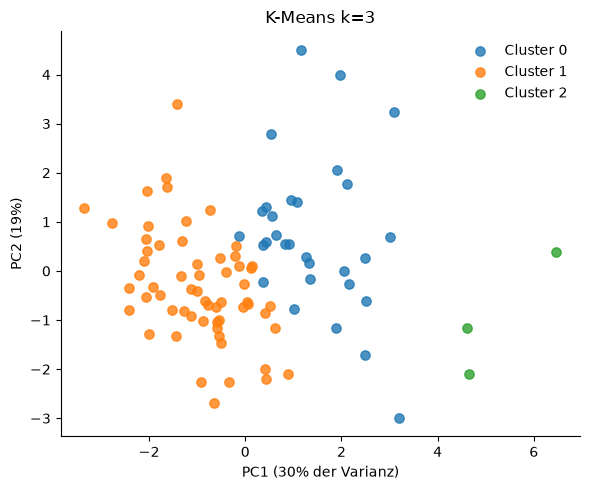

Ladungen, sortiert nach |PC1|:


,PC1,PC2
rt_mean_winter,0.48,0.33
idle_share,-0.42,0.23
flow_short_cycle_power,-0.39,-0.06
dt_mean_loaded,-0.37,-0.37
summer_flow_baseline,0.37,0.03
full_load_hours,0.33,-0.42
dt_std_loaded,-0.17,0.23
peak_load_share,-0.12,0.57
flow_ceiling_slope_per_month,-0.10,-0.25
p95_load_share,-0.06,0.28


--- Cluster-Mediane der fachlichen Achsen (K-Means k=3)


,rt_mean_winter,dt_mean_loaded,summer_flow_baseline,n_hast
cluster,,,,
0,53.55,16.20,42.0,30
1,41.88,28.47,0.0,60
2,61.88,11.63,2270.0,3


In [9]:
fig, axes = plt.subplots(1, len(X_varianten), figsize=(6 * len(X_varianten), 5), squeeze=False)
axes = axes[0]
palette = plt.cm.tab10.colors
for ax, (vname, X) in zip(axes, X_varianten.items()):
    pca = PCA(n_components=2, random_state=SEED)
    coords = pca.fit_transform(X)
    ev = pca.explained_variance_ratio_
    for c in sorted(set(labels_k3[vname]["K-Means"])):
        mask = labels_k3[vname]["K-Means"] == c
        ax.scatter(coords[mask, 0], coords[mask, 1], s=45, alpha=0.8,
                   color=palette[c % len(palette)], label=f"Cluster {c}")
    ax.set(title=f"K-Means k={K}",
           xlabel=f"PC1 ({ev[0]:.0%} der Varianz)", ylabel=f"PC2 ({ev[1]:.0%})")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

pca = PCA(n_components=2, random_state=SEED).fit(X_varianten["HAST"])
loadings = pd.DataFrame(pca.components_.T, index=CLUSTER_FEATURES, columns=["PC1", "PC2"])
print("Ladungen, sortiert nach |PC1|:")
display(loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).round(2))

achsen = ["rt_mean_winter", "dt_mean_loaded", "summer_flow_baseline"]
for vname, df in varianten.items():
    prof = df.assign(cluster=labels_k3[vname]["K-Means"]).groupby("cluster")[achsen].median()
    prof["n_hast"] = pd.Series(labels_k3[vname]["K-Means"]).value_counts().sort_index()
    print(f"--- Cluster-Mediane der fachlichen Achsen (K-Means k={K})")
    display(prof.round(2))

- Zwei PCA-Dimensionen erfassen nur 48,5 % der Varianz. Die Ebene ist eine grobe Projektion.
- PC1 wird getragen von `rt_mean_winter` (0,48), `idle_share` (−0,42) und `flow_short_cycle_power` (−0,39), dazu Spreizung und Sommerdurchfluss. Die Rücklauf-Spreizungs-Achse ist die Hauptstreurichtung, wie in Notebook 07.
- Cluster-Mediane (K-Means, k = 3): Cluster 1 (n = 60) unauffällig mit Rücklauf 41,9 °C, Spreizung 28,5 K und ohne Sommerdurchfluss. Cluster 0 (n = 30) ist die schwach gespreizte Gruppe mit Winterrücklauf 53,6 °C bei Spreizung 16,2 K. Cluster 2 (n = 3) sind Ausreißer (61,9 °C, Sommerdurchfluss 2 270 l/h).
- Die Richtung der Trennung stimmt. Das Problem sind die fließenden Übergänge (Silhouette unter 0,25).

## 9 Abgleich mit den Begehungen (Ground Truth)

- Join über die normalisierte Adresse (`_normalize_address` aus `src/load_data.py`). Label je Station: mindestens eine dokumentierte Maßnahme (`n_actions` > 0).
- Je Cluster: Anteil mit Maßnahme, Fisher-Test (Cluster gegen Rest, Maßnahme ja oder nein) und Mann-Whitney-Test auf `n_actions`.
- Basisrate beachten: Ein fast konstantes Label kann nichts trennen. Das ist ein methodischer Befund, kein Modellfehler.
- Cluster ohne Station im Join werden benannt statt gerechnet.

In [10]:
insp = pd.read_csv(INSPECTIONS_PATH)
gt = insp.groupby("address_norm").agg(
    n_begehungen=("address_norm", "size"),
    n_actions=("n_actions", "sum"),
).reset_index()
gt["massnahme"] = gt["n_actions"] > 0

gt_joins = {}
for vname, df in varianten.items():
    j = df.copy()
    j["address_norm"] = j["address"].apply(_normalize_address)
    j = j.merge(gt, on="address_norm", how="inner")
    gt_joins[vname] = j
    rate = j["massnahme"].mean()
    print(f"{len(j)} Stationen im GT-Join, "
          f"Basisrate 'mind. eine Maßnahme' = {rate:.0%}")


def gt_tabelle(vname, mname, labels):
    df = varianten[vname]
    j = gt_joins[vname].copy()
    lab_series = pd.Series(labels, index=df["Zählernummer"].to_numpy())
    j["cluster"] = j["Zählernummer"].map(lab_series)
    rows = []
    for c in sorted(set(labels)):
        a = j[j["cluster"] == c]
        b = j[j["cluster"] != c]
        n_total = int((np.asarray(labels) == c).sum())
        if len(a) == 0 or len(b) == 0:
            rows.append({"cluster": int(c), "n_hast": n_total, "n_im_join": len(a),
                         "anteil_massnahme": np.nan, "fisher_p": np.nan, "mwu_p": np.nan})
            continue
        tabelle = [[int(a["massnahme"].sum()), int((~a["massnahme"]).sum())],
                   [int(b["massnahme"].sum()), int((~b["massnahme"]).sum())]]
        p_f = stats.fisher_exact(tabelle)[1]
        p_u = stats.mannwhitneyu(a["n_actions"], b["n_actions"]).pvalue
        rows.append({"cluster": int(c), "n_hast": n_total, "n_im_join": len(a),
                     "anteil_massnahme": a["massnahme"].mean(),
                     "fisher_p": p_f, "mwu_p": p_u})
    return pd.DataFrame(rows)


gt_ergebnisse = {}
for vname in varianten:
    for mname in FITTER:
        tab = gt_tabelle(vname, mname, labels_k3[vname][mname])
        gt_ergebnisse[(vname, mname)] = tab
        print(f"--- {mname} (k={K})")
        display(tab.round(3))

56 Stationen im GT-Join, Basisrate 'mind. eine Maßnahme' = 77%
--- K-Means (k=3)


,cluster,n_hast,n_im_join,anteil_massnahme,fisher_p,mwu_p
0,0,30,17,0.765,1.0,0.76
1,1,60,39,0.769,1.0,0.76
2,2,3,0,NaN,NaN,NaN


--- Ward (k=3)


,cluster,n_hast,n_im_join,anteil_massnahme,fisher_p,mwu_p
0,0,4,0,NaN,NaN,NaN
1,1,57,33,0.818,0.344,0.436
2,2,32,23,0.696,0.344,0.436


--- GMM (k=3)


,cluster,n_hast,n_im_join,anteil_massnahme,fisher_p,mwu_p
0,0,16,11,0.727,0.705,0.740
1,1,20,8,0.625,0.370,0.080
2,2,57,37,0.811,0.329,0.314


- 56 Stationen im Join, Basisrate „mindestens eine Maßnahme“ 77 %. Die entfernten Nicht-HAST standen ohnehin nicht in den Begehungsdaten.
- Gegenüber dem vorigen Lauf (55 Stationen, 80 %) leicht verschoben: Die Adresse kommt jetzt bevorzugt aus `Zuordnung.xlsx` (siehe `src/features.py`). Eine Station (80912177) hat dort je nach Jahr zwei verschiedene Adressangaben; die jüngere trifft die Begehungsadresse nicht mehr. Zwei andere Stationen kamen hinzu.
- Kein Cluster unterscheidet sich signifikant vom Rest: Fisher p ≥ 0,33, Mann-Whitney p ≥ 0,08, über alle Verfahren. Die Anteile mit Maßnahme liegen bei 63 bis 82 %, also um die Basisrate.
- Der Ausreißer-Cluster (n = 3 bzw. 4) hat 0 Stationen im Join und ist nicht testbar (NaN statt p-Wert). Bei 77 % Basisrate könnte selbst ein perfektes Clustering kaum trennen; die Labelqualität bleibt der Engpass.

## 10 Ergebnisse speichern

- Eine Zeile je HAST mit den Zuordnungen aller vier Verfahren nach `data/processed/cluster_benchmark.csv`. HDBSCAN-Rauschen steht als −1 in der Datei.
- `cluster_benchmark.json` daneben: Verfahren, k, Silhouette, Größen, Bootstrap-ARI, Seed und die in Notebook 00 entfernten Zähler. So ist der Lauf ohne Neuberechnung nachvollziehbar.

In [11]:
out_path = ROOT / "data" / "processed" / "cluster_benchmark.csv"
out = features_all[["Zählernummer", "address", "coverage"]].copy()
for vname, df in varianten.items():
    meters = df["Zählernummer"].to_numpy()
    for mname in FITTER:
        spalte = f"cluster_{mname.lower().replace('-', '')}"
        out[spalte] = out["Zählernummer"].map(pd.Series(labels_k3[vname][mname], index=meters))
    spalte = "cluster_hdbscan"
    out[spalte] = out["Zählernummer"].map(pd.Series(hdbscan_labels[vname], index=meters))
out.to_csv(out_path, index=False)

meta = {
    "erzeugt": pd.Timestamp.now().isoformat(timespec="seconds"),
    "quelle": str(FEATURES_PATH.relative_to(ROOT)),
    "k": K,
    "random_state": SEED,
    "vorverarbeitung": "Median-Imputation -> Clipping 1./99. Perzentil -> StandardScaler",
    "cluster_features": CLUSTER_FEATURES,
    "nicht_hast_in_nb00_entfernt": sorted(NICHT_HAST),
    "hdbscan_min_cluster_size": 3,
    "bootstrap": {"n_boot": 25, "methode": "Refit auf Stichprobe, Nächstes-Zentroid-Übertragung"},
    "varianten": {},
}
for vname in varianten:
    vmeta = {"n_hast": int(len(varianten[vname])), "verfahren": {}}
    for mname in FITTER:
        lab = labels_k3[vname][mname]
        sil_row = ergebnis[(ergebnis["variante"] == vname) &
                           (ergebnis["verfahren"] == mname) &
                           (ergebnis["k"] == K)]
        stab_row = stabilitaet[(stabilitaet["variante"] == vname) &
                               (stabilitaet["verfahren"] == mname) &
                               (stabilitaet["k"] == K)]
        vmeta["verfahren"][mname] = {
            "silhouette": round(float(sil_row["silhouette"].iloc[0]), 4),
            "clustergroessen": groessen(lab),
            "bootstrap_ari_mean": round(float(stab_row["ari_mean"].iloc[0]), 4),
        }
    lab = hdbscan_labels[vname]
    ok = lab != -1
    stab_row = stabilitaet[(stabilitaet["variante"] == vname) &
                           (stabilitaet["verfahren"] == "HDBSCAN mcs=3")]
    vmeta["verfahren"]["HDBSCAN"] = {
        "silhouette": round(float(sichere_silhouette(X_varianten[vname][ok], lab[ok])), 4),
        "clustergroessen": groessen(lab[ok]) + f" (+{int((~ok).sum())} Rauschen)",
        "bootstrap_ari_mean": round(float(stab_row["ari_mean"].iloc[0]), 4),
    }
    meta["varianten"][vname] = vmeta

meta_path = out_path.with_suffix(".json")
meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Cluster-Zuordnungen -> {out_path}")
print(f"Lauf-Kontext        -> {meta_path}")

Cluster-Zuordnungen -> /Users/ivelinayaneva/projektseminar/data/processed/cluster_benchmark.csv
Lauf-Kontext        -> /Users/ivelinayaneva/projektseminar/data/processed/cluster_benchmark.json


## Zusammenfassung & Bewertung

**Ergebnis**
- Lauf auf den 93 HAST aus Notebook 00.

| Verfahren | k | Silhouette | Größen | Bootstrap-ARI |
|---|---|---|---|---|
| K-Means | 2 | 0,237 | 31/62 | 0,67 |
| K-Means | 3 | 0,219 | 30/60/3 | 0,45 |
| Ward | 2 | 0,179 | 36/57 | 0,28 |
| Ward | 3 | 0,164 | 4/57/32 | 0,31 |
| GMM | 2 | 0,312 | 76/17 | 0,43 |
| GMM | 3 | 0,156 | 16/20/57 | 0,36 |
| HDBSCAN mcs=3 | – | 0,217 | 44/4 (+45 Rauschen) | 0,06 |
| HDBSCAN mcs=5/8 | – | – | alles Rauschen | – |

- k ≥ 4 wurde für alle Verfahren gerechnet (Abschnitte 5 und 6). Es zerlegt die Masse nur weiter, ohne bessere Silhouette.
- Bestes Verfahren: K-Means, am stabilsten bei k = 2.

**Belastbar**
- Die Ausreißer 58202380 und 66761022 sind der robusteste Einzelbefund: K-Means und Ward trennen beide bei k = 3 als Kleinst-Cluster ab (Winterrücklauf über 60 °C, Sommerdurchfluss über 2 000 l/h, `idle_share` nahe 0). GMM sieht sie nicht als eigene Gruppe.
- Die Trennungsachse ist fachlich richtig: PC1 = Rücklauf, Leerlauf und Spreizung. Die schwach gespreizte Gruppe (n = 30) mit Rücklauf 53,6 °C bei Spreizung 16,2 K ist die fachlich interessante Gruppe.
- K-Means ist am stabilsten (ARI 0,67 bei k = 2, 0,45 bei k = 3), aber deutlich unter dem alten Referenzwert 0,90.
- Nachtrag aus Notebook 09: Auf der Stundenebene liegt der Bootstrap-ARI bei k = 5 bei 0,851. Der Wert ist nach oben verzerrt (rund 1,68 Mio. Stunden statt 93 Stationen), zeigt aber, dass die Stundenpartition nicht am Seed hängt.

**Schwach**
- Keine belastbare Clusterstruktur: Nur GMM mit k = 2 liegt knapp über 0,25 (0,312 bei 76/17), alle anderen darunter.
- Die Verfahren sind sich nur über die Ausreißer einig (paarweiser ARI 0,35 bis 0,48). Die Struktur der Masse hängt vom Verfahren ab.
- HDBSCAN: ab mcs = 5 alles Rauschen, mcs = 3 lässt rund die Hälfte der Stationen unzugeordnet. Dichtebasiertes Clustering trägt auf diesen Merkmalen nicht.
- Die Begehungen trennen nichts: kein Cluster signifikant maßnahmenreicher (Fisher p ≥ 0,33, Mann-Whitney p ≥ 0,08), Basisrate 77 %. Der interessanteste Cluster (die Ausreißer) fehlt in den Begehungsdaten ganz.
- Nachtrag aus Notebook 09: Zwölf Merkmalspaare korrelieren mit einem Betrag über 0,8; die Größenachse zählt in der Distanz mehrfach. Redundanzabbau hebt die Silhouette bei k = 3 nur von 0,261 auf 0,272, die Stabilität sinkt dabei (ARI 0,87 auf 0,53).

**Offen**
- Fachliche Prüfung von 58202380 und 66761022: auch über `Zuordnung.xlsx` keiner Adresse zugeordnet, beide fehlen in den Begehungsdaten. Der dritte Ausreißer 86792512 ist laut ÜZ ein BHKW und fällt seit Notebook 00 raus.